# From test results to risk classes, deadlines, opinions and appetite

**Question:** How do the results of the validation tests become a class for each model, a deadline for each finding, an opinion on each model and a light for the whole inventory, and which of those verdicts rest on a convention rather than on the evidence?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic (the size and power of the tests whose results are being governed)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- read the six governance documents of the product and say what each holds, from the models record of case C22 to the appetite metrics;
- recompute with the engine the class of every inventory entry from its scores, and place it on the 4 by 4 matrix;
- say how many models change class when the rubric is read in another of its four ways, and how the class count depends on the cut points of the exposure band;
- recompute the deadline and the due date of every finding of the register and the opinion each model receives from its open findings;
- recompute the seven appetite metrics and the golden lights of the engine contract, and run the whole chain on a model of your own.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with
import importlib.metadata as md
import json
from collections import Counter
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.1.0
numpy 2.4.6
matplotlib 3.11.2


## Data

The data are the documents that the governance layer of the product writes from the results of every case, read from `data/derived/` and from the contract fixtures; no raw data is read. All of them are generated by the product from its own committed results (licence class `generated`).

- **Models record of C22** (`data/derived/C22/models-generators.json`, contract `c22-models`): `model`, `fit` with its `studies` (the named size and power studies, with their fixed arguments, repetitions and seeds) and its `parity` rows, `provenance` and `lane`.
- **Inventory** (`governance/inventory.json`, contract `governance-inventory`): `entries`, one per model, each with 40 `attributes` that carry a `value`, a `status` and a `basis`, a `tier_block`, a `lifecycle`, a `schedule` and a `scope`; the `edges` between entries; `completeness`, `tier_counts` and the inventory's own `governance_findings`.
- **Findings register** (`governance/findings.json`, contract `governance-findings`): `rows`, each a finding of one variant with its `severity`, `status`, `class`, `raised`, `deadline_days`, `due`, `overdue` and `rwea_share`, and the `conventions` that fixed them.
- **Report** (`governance/reports/C22-generators.json`, contract `governance-report`): the twelve `sections` of the validation report of one entry.
- **Appetite** (`governance/appetite.json`, contract `governance-appetite`): seven `metrics`, each with its `value`, `numerator`, `denominator` and `light`.
- **Fixture** (`docs/contracts/fixtures/governance/inventory-fixture.json`): the four-entry inventory on which the engine contract states its golden values (`engine-governance-api`).

The next cell loads them and prints their sizes.

In [2]:
# Load the six governance documents and print what each holds
LANG = "en"
ROOT = Path("../../..").resolve()
GOV = ROOT / "data" / "derived" / "governance"
read = lambda path: json.loads(path.read_text(encoding="utf-8"))
models = read(ROOT / "data" / "derived" / "C22" / "models-generators.json")
inventory, findings, appetite = (read(GOV / f"{name}.json") for name in ("inventory", "findings", "appetite"))
report = read(GOV / "reports" / "C22-generators.json")
fixture = read(ROOT / "docs" / "contracts" / "fixtures" / "governance" / "inventory-fixture.json")
entries, rows = inventory["entries"], findings["rows"]
print("inventory entries:", len(entries), "| register rows:", len(rows), "| as of:", findings["as_of"])
print("size and power studies of C22:", len(models["fit"]["studies"]))
print("parity rows:", len(models["fit"]["parity"]))
print("report of:", report["entry_key"], "| sections:", len(report["sections"]))

inventory entries: 34 | register rows: 745 | as of: 2026-11-08
size and power studies of C22: 25
parity rows: 564
report of: C22/generators | sections: 12


## Method

The governance layer applies three rules to the results, and each is a convention that the product states and the engine implements; the notebook runs the engine's functions and never re-implements them. The class of a model comes from a materiality $M$ and a complexity $C$, each from 1 to 4 (the dossier's rubric; Federal Reserve SR 11-7 and PRA SS1/23 are the supervisory texts on model risk management):

$$M = \max\bigl(\text{band},\ \text{use},\ \text{criticality}\bigr), \qquad C = \Bigl\lfloor \tfrac{2\sum_i s_i + n}{2n} \Bigr\rfloor,$$

where band is the exposure band of the model's share of the balance, use the regulatory-use grade, criticality the decision-criticality score, $s_i$ the $n$ scored complexity factors, and the second expression the mean rounded half up in integer arithmetic. The class is a function $T(M, C)$ of the 4 by 4 matrix, with class 1 the highest. A finding of severity $\sigma$ in a model of class $\tau$ must be remediated within $d(\sigma, \tau)$ days of being raised, from a table that never grows when the severity or the class rises, and the opinion on a model is

$$L = \max_{f \in \text{open}} \max\bigl(L_\sigma(f),\ L_{\text{RWEA}}(f)\bigr),$$

the highest level among its open findings, where $L_\sigma$ is 4 for a critical finding, 3 for a major one and 2 for the rest, and $L_{\text{RWEA}}$ is 3 from a share of 5% of risk-weighted exposure and 4 from 10% (ECB, 2019, section 2.4.2). The appetite metrics count and compare against thresholds that are also conventions. The steps below read each rule in the committed documents, recompute it with the engine and compare.

### Step 1: the models record and the inventory

The inventory registers each validated model with 40 attributes, and an attribute is honest about where its value comes from: `present` (read at a path), `derivable`, `convention`, `not_applicable` or `missing`. The next cell prints the sizes of the models record of C22, which is what the inventory entry C22/generators points to, counts the status of the 1,360 attribute cells and lists the attributes that no entry holds.

attribute cells: 1360 | {'present': 310, 'derivable': 327, 'convention': 204, 'not_applicable': 102, 'missing': 417}
attributes missing in every entry: 10 of 40


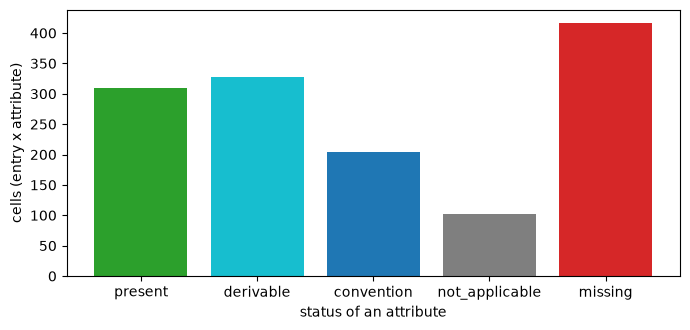

In [3]:
# Count the status of the 40 attributes of the 34 entries
statuses = ("present", "derivable", "convention", "not_applicable", "missing")
totals = Counter()
for counts in inventory["completeness"]["attributes"].values():
    totals.update(counts)
never = [a for a, c in inventory["completeness"]["attributes"].items() if c["missing"] == len(entries)]
print("attribute cells:", sum(totals.values()), "|", {s: totals[s] for s in statuses})
print("attributes missing in every entry:", len(never), "of 40")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(statuses, [totals[s] for s in statuses], color=["tab:green", "tab:cyan", "tab:blue", "tab:gray", "tab:red"])
ax.set_xlabel("status of an attribute")
ax.set_ylabel("cells (entry x attribute)")
fig.tight_layout()
plt.show()

The 34 entries have 1,360 attribute cells: 310 present, 327 derivable, 204 conventions, 102 not applicable and 417 missing. Ten of the 40 attributes are missing in every entry. The figure is the honest part of the inventory: nearly one cell in three is a gap that the product records and does not fill, because no document says whether alternative data is used or what the known limitations are. The models record has 25 named studies and 564 parity rows, so the C22 entry is backed by the same sizes and powers that the notebooks of this topic measure; the figure does not say which gaps matter, only how many there are.

### Step 2: the class of every entry

The next cell recomputes the class of the 34 entries with `tiering.materiality`, `tiering.complexity` and `tiering.matrix_tier` from the scores in each `tier_block`, checks them against the committed classes and draws how many entries fall in each cell of the matrix, with the class of each cell written in it.

classes equal to the committed ones: True
entries in classes 1 to 4: (18, 15, 0, 1)


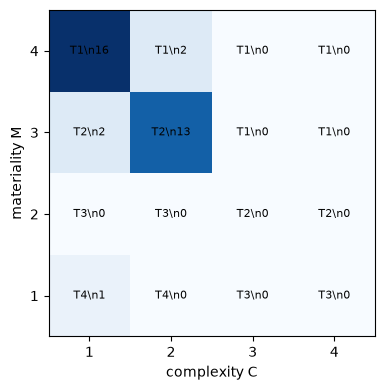

In [4]:
# Recompute the class of every entry from its scores with the engine and place it on the matrix
from riskvalidation.governance import tiering

grid = np.zeros((4, 4), int)
tiers, inputs = [], []
for entry in entries:
    block = entry["tier_block"]
    band = block["materiality"]["exposure"]["band"]
    graded = block["materiality"]["regulatory_use"]["graded"]
    m = tiering.materiality(band, graded, block["materiality"]["decision_criticality"]["score"])
    c = tiering.complexity([f["score"] for f in block["complexity"]["factors"] if f["score"] is not None])
    tiers.append(tiering.matrix_tier(m, c))
    share = block["materiality"]["exposure"]["share"]
    inputs.append((share, graded, block["materiality"]["decision_criticality"]["score"], c))
    grid[m - 1, c - 1] += 1
print("classes equal to the committed ones:", all(t == e["tier_block"]["tier"] for t, e in zip(tiers, entries)))
print("entries in classes 1 to 4:", tiering.tier_counts(tiers))
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(grid, origin="lower", cmap="Blues")
for m in range(4):
    for c in range(4):
        ax.text(c, m, f"T{tiering.matrix_tier(m + 1, c + 1)}\\n{grid[m, c]}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(4), ["1", "2", "3", "4"])
ax.set_yticks(range(4), ["1", "2", "3", "4"])
ax.set_xlabel("complexity C")
ax.set_ylabel("materiality M")
fig.tight_layout()
plt.show()

All 34 recomputed classes equal the committed ones, and the entries fall in class 1 (18 entries), class 2 (15), class 3 (none) and class 4 (1). No entry falls in a cell of the matrix that gives class 3, and the figure shows where the 34 entries sit, so that a reader can see which score would have to change to move one.

### Step 3: the same inventory under the four readings

The rubric leaves two choices open: whether the regulatory use is graded or literal, and whether the complexity is the mean or the maximum of its factors. The engine's `tier_sensitivity` returns the class under the four combinations, A (literal, mean), B (graded, mean, the adopted reading), C (literal, maximum) and D (graded, maximum). The next cell reads them from each entry and counts the classes under each reading.

A (33, 0, 0, 1)
B (18, 15, 0, 1)
C (33, 0, 0, 1)
D (31, 2, 0, 1)


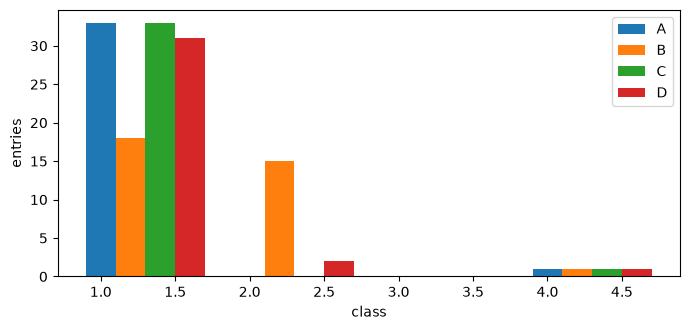

In [5]:
# Read the class of each entry under the four readings of the rubric
readings = {"A": [], "B": [], "C": [], "D": []}
for entry in entries:
    for item in entry["tier_block"]["tier_sensitivity"]:
        readings[item["reading"]].append(item["tier"])
width = 0.2
fig, ax = plt.subplots(figsize=(7, 3.4))
for index, (name, values) in enumerate(readings.items()):
    counts = tiering.tier_counts(values)
    ax.bar(np.arange(1, 5) + index * width, counts, width, label=name)
    print(name, counts)
ax.set_xlabel("class")
ax.set_ylabel("entries")
ax.legend()
fig.tight_layout()
plt.show()

Reading B, the adopted one, puts 18 entries in class 1 and 15 in class 2. Readings A and C put 33 in class 1 and none in class 2, and D puts 31 and 2. One entry, the generator case, is class 4 under all four. The choice of reading therefore moves 15 models from class 2 to class 1 and with it their review cycle and their deadlines; the figure shows that the class is not a fact but a reading, and that the product shows the other three beside the adopted one.

### Step 4: deadlines and the severity scale

A finding's deadline is `deadline_days(severity, class)` days from `raised`, its due date `due_date(raised, days)`, and its ECB level `severity_to_ecb`. The cell recomputes both for each row of the register, counts the rows that differ from the committed ones and draws the deadline table.

rows whose deadline or due date differ: 0 of 745
severity to ECB level: {'S1': 'F4', 'S2': 'F3', 'S3': 'F2', 'S4': 'F1'}


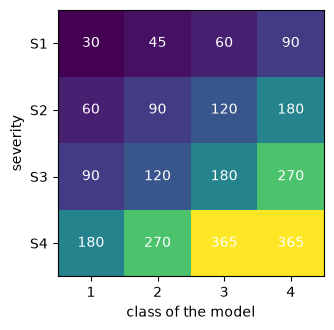

In [6]:
# Recompute the deadline and the due date of every finding and draw the deadline table
from riskvalidation.governance import findings as gf

mismatch = 0
for row in rows:
    days = gf.deadline_days(row["severity"], row["tier"])
    due = gf.due_date(date.fromisoformat(row["raised"]), days)
    mismatch += (days != row["deadline_days"]) or (due.isoformat() != row["due"])
print("rows whose deadline or due date differ:", mismatch, "of", len(rows))
print("severity to ECB level:", {s: gf.severity_to_ecb(s) for s in ("S1", "S2", "S3", "S4")})
table = np.array([[gf.deadline_days(s, t) for t in range(1, 5)] for s in ("S1", "S2", "S3", "S4")])
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.imshow(table, cmap="viridis")
for i in range(4):
    for j in range(4):
        ax.text(j, i, table[i, j], ha="center", va="center", color="white")
ax.set_xticks(range(4), ["1", "2", "3", "4"])
ax.set_yticks(range(4), ["S1", "S2", "S3", "S4"])
ax.set_xlabel("class of the model")
ax.set_ylabel("severity")
fig.tight_layout()
plt.show()

No row of the register differs: the committed deadlines and due dates are the engine's. The table is monotone, as the engine invariant requires: a critical finding in a class 1 model must be closed in 30 days, a minor one in a class 4 model in 365, and the numbers are a convention (dossier item 30), not a regulation. The mapping from S1, S2, S3 and S4 to F4, F3, F2 and F1 keeps the product's direction, with S1 the most severe, and reads the ECB's scale.

### Step 5: the opinion on each model

The opinion takes only the open findings (open, with an action plan, in progress, submitted for closure or overdue); an accepted or closed finding does not count. The cell builds each entry's list of (severity, share of RWEA) pairs, applies `opinion_level` and prints the number of entries per level and the recommendation of each level.

In [7]:
# Give each model the opinion its open findings produce
from riskvalidation.governance import opinion

OPEN = {"open", "action_plan_agreed", "in_progress", "submitted_for_closure", "overdue"}
by_entry = {}
for row in rows:
    if row["status"] in OPEN:
        by_entry.setdefault(row["entry_key"], []).append((row["severity"], row["rwea_share"]))
levels = {key: opinion.opinion_level(items) for key, items in by_entry.items()}
print("entries by opinion level:", dict(sorted(Counter(levels.values()).items())))
print("entries with no open finding:", len(entries) - len(by_entry))
for level in (1, 2, 3, 4):
    print(level, opinion.recommendation(level)[0])

entries by opinion level: {3: 32, 4: 2}
entries with no open finding: 0
1 approve
2 approve with conditions
3 remediate before use
4 remediate before use


Thirty-two entries receive level 3 and two receive level 4, and every entry has at least one open finding. The recommendation of levels 3 and 4 is the same, remediate before use, and the engine labels it the rule's output on the evidence: Contraste approves no model. A validator should read the figure as saying that the committed inventory contains no model that the rule would pass without conditions, which follows from the findings the tests raise on generated data, not from a judgement on the models.

### Step 6: the appetite metrics and the contract's golden values

Seven metrics summarise the register against thresholds. The cell recomputes them with `appetite_metrics` from the entries and rows, sets each against the committed value and light, counts the inventory's own open findings of severity S1 or S2 that the register does not hold, and runs the engine on the four-entry fixture, whose lights the contract states as green, red, amber, green, red, green, red.

In [8]:
# Recompute the seven appetite metrics and the fixture of the contract
from riskvalidation.governance import appetite as ga

today = date.fromisoformat(appetite["as_of"])
live = ga.appetite_metrics(entries, rows, today)
fixture_rows = read(ROOT / "docs" / "contracts" / "fixtures" / "governance" / "findings-fixture.json")["rows"]
golden = ga.appetite_metrics(fixture["entries"], fixture_rows, date(2026, 12, 31))
for item, kept in zip(live, appetite["metrics"]):
    print(f"{item['id']:26s} {item['value']!s:.8s} {item['light']:6s}", end=" ")
    print(f"| committed {kept['value']!s:.8s} {kept['light']}")
extra = sum(g["severity"] in ("S1", "S2") and g["status"] == "open" for g in inventory["governance_findings"])
print("open S1 or S2 findings of the inventory itself:", extra, "| register plus those:", live[1]["value"] + extra)
print("fixture lights:", [item["light"] for item in golden])

tier1-validated-on-time    1.0 green  | committed 1.0 green
open-high-severity         144 red    | committed 145 red
overdue-remediation        0 green  | committed 0 green
entries-under-exception    0 green  | committed 0 green
entries-in-breach          32 red    | committed 32 red
pma-magnitude              0.003321 green  | committed 0.003321 green
owner-and-complete-record  0.0 red    | committed 0.0 red
open S1 or S2 findings of the inventory itself: 1 | register plus those: 145
fixture lights: ['green', 'red', 'amber', 'green', 'red', 'green', 'red']


Six metrics reproduce exactly. The open high-severity count is 144 here and 145 in the committed file, both red: the inventory carries two findings of its own, and one of them is open with severity S2, which the register does not hold; 144 plus 1 is the committed 145. On the fixture the engine returns the lights the contract states, in order green, red, amber, green, red, green and red, which is the check of the engine against its contract. Four of the seven lights are green and three red; the owner-and-complete-record metric is 0.0 and red because every entry has missing attributes, as step 1 showed.

### Where the method changes or breaks

Two numbers decide the verdicts above and neither is measured: the RWEA share at which a finding rises a level, and the cut points of the exposure band. The first cell sweeps the share from 0 to 15% for findings of severity S1, S3 and S4 and prints where the level changes; the second sweeps the top cut point of the band from 15% to 50% and counts the classes, keeping the other cuts at 10% and 2%.

S1 level changes at the shares []
S3 level changes at the shares [0.05, 0.1]
S4 level changes at the shares [0.05, 0.1]


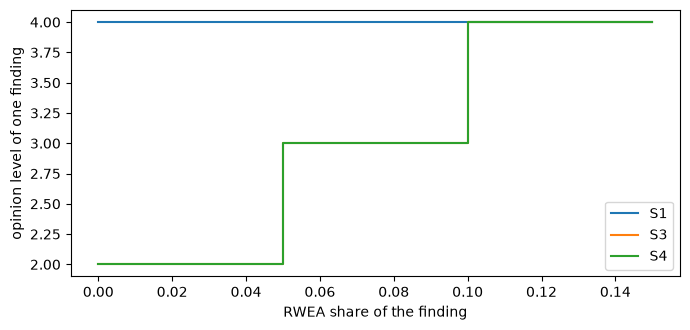

top cut point 0.15 {1: 28, 2: 5, 4: 1}
top cut point 0.2 {1: 26, 2: 7, 4: 1}
top cut point 0.25 {1: 18, 2: 15, 4: 1}
top cut point 0.35 {1: 14, 2: 19, 4: 1}
top cut point 0.5 {1: 14, 2: 19, 4: 1}


In [9]:
# Sweep the RWEA share of a finding and the top cut point of the exposure band
shares = np.linspace(0.0, 0.15, 301)
fig, ax = plt.subplots(figsize=(7, 3.4))
for severity in ("S1", "S3", "S4"):
    steps = [opinion.finding_level(severity, share) for share in shares]
    ax.step(shares, steps, where="post", label=severity)
    jumps = [round(float(shares[i]), 4) for i in range(1, len(steps)) if steps[i] != steps[i - 1]]
    print(severity, "level changes at the shares", jumps)
ax.set_xlabel("RWEA share of the finding")
ax.set_ylabel("opinion level of one finding")
ax.legend()
fig.tight_layout()
plt.show()
cuts_grid = (0.15, 0.20, 0.25, 0.35, 0.50)
for top in cuts_grid:
    counts = Counter()
    for share, graded, criticality, c in inputs:
        band = tiering.exposure_band(share, (top, 0.10, 0.02))
        counts[tiering.matrix_tier(tiering.materiality(band, graded, criticality), c)] += 1
    print("top cut point", top, dict(sorted(counts.items())))

A critical finding is level 4 at every share, so no share changes it. A major or minor finding (S3, S4) changes at exactly two points, 5% and 10%, the levels 3 and 4 of the ECB instruction, which is why a small anchor can raise a minor finding to a level that blocks use. The class counts move with the top cut point: with 15% there are 28 entries in class 1 and 5 in class 2, with 20% 26 and 7, with 25% (the product's cut) 18 and 15, and with 35% 14 and 19, and the counts do not change between 35% and 50%. The regime where the verdict breaks is a book whose exposure shares sit near a cut: moving the cut from 25% to 20% moves eight models between classes, and the committed documents record that choice as a convention and do not test it.

### Using it on your own data

The chain needs, for one model, the share of the balance it covers, the regulatory-use grade (1 to 4), the decision-criticality score (1 to 4), the complexity factor scores (1 to 4 each) and, for each finding, its severity, the date it was raised and, when the anchor is a share of RWEA, that share. `tiering.exposure_band`, `materiality`, `complexity` and `matrix_tier` give the class; `apply_override` takes the class and an optional (new class, rationale, approver) and refuses an override with an empty rationale or approver; `findings.deadline_days`, `due_date` and `is_overdue` give the deadlines; `opinion.opinion_level` and `recommendation` give the opinion; `appetite.light` turns a count into a colour. The cell below runs the chain on an illustrative model with 8% of the balance, a graded use of 3, a criticality of 2, six complexity scores and two findings raised on 1 September 2026, read on 31 December.

In [10]:
# Run the whole chain on one model of your own: class, deadlines, opinion, light
share, graded_use, criticality = 0.08, 3, 2
scores = [3, 2, 2, 1, 1, 1]
m = tiering.materiality(tiering.exposure_band(share), graded_use, criticality)
c = tiering.complexity(scores)
tier = tiering.matrix_tier(m, c)
final = tiering.apply_override(tier, (1, "the model feeds the stress test", "Chief Risk Officer"))
print("M", m, "| C", c, "| class:", tier, "| after the override:", final)
raised, as_of = date(2026, 9, 1), date(2026, 12, 31)
items = [("S2", 0.06), ("S3", None)]
for severity, share_rwea in items:
    days = gf.deadline_days(severity, final)
    due = gf.due_date(raised, days)
    print(severity, "deadline days:", days, "| due:", due, "| overdue:", gf.is_overdue("open", due, as_of))
level = opinion.opinion_level(items)
print("opinion level:", level, "|", opinion.recommendation(level)[0])
print("light of two overdue findings against 0 and 3:", ga.light(2, "lower-is-better", 0, 3))

M 3 | C 2 | class: 2 | after the override: 1
S2 deadline days: 60 | due: 2026-10-31 | overdue: True
S3 deadline days: 90 | due: 2026-11-30 | overdue: True
opinion level: 3 | remediate before use
light of two overdue findings against 0 and 3: amber


The model has materiality 3 and complexity 2, so it is class 2, and the override with a stated rationale and approver takes it to class 1. Its S2 finding has 60 days and falls due on 31 October 2026, its S3 finding 90 days and 30 November, and both are overdue on 31 December. The opinion is level 3, remediate before use, driven by the S2 finding with 6% of RWEA, and two overdue findings against thresholds of 0 and 3 give amber. When you adapt the cell, check that the override carries a real rationale and approver, since an empty one raises an error by design; that the findings you pass to the opinion are only the open ones; and that the status you pass to `is_overdue` is the workflow state and not the product status, because a risk-accepted finding is never overdue.

## Results

**Answer:** The results become a class through a matrix of materiality and complexity, a deadline through a table of severity and class, an opinion through the highest level among open findings, and a light through seven counted metrics, and the engine reproduces every committed value: all 34 classes, every deadline and due date of the register, and six of the seven appetite values, the seventh differing by the one open S2 finding of the inventory itself (144 against 145). The verdicts rest on conventions more than on evidence: reading the rubric another way moves 15 of 34 models from class 2 to class 1, and moving the top cut point of the exposure band from 25% to 20% moves eight.

- **The inventory is honest about its gaps.** 417 of 1,360 attribute cells are missing, and ten attributes are missing everywhere.
- **The opinion is uniform here.** 32 entries are at level 3 and 2 at level 4, none at level 1 or 2, because every model has open findings.
- **The engine meets its contract.** The fixture returns the lights green, red, amber, green, red, green and red.

What this notebook does not do is judge a model: the layer applies stated rules to the results and says so in every label.

## Summary

- The governance layer turns test results into a class, a deadline, an opinion and an appetite light with functions of `riskvalidation.governance`, which a notebook calls and never re-implements.
- The 34 classes, every deadline and due date of the register and six of seven appetite metrics recompute exactly; the seventh differs by one finding that the inventory holds itself.
- The class is a reading: four readings of the rubric give 18, 33, 33 and 31 entries in class 1.
- A finding rises to level 3 at 5% of RWEA and to level 4 at 10%, whatever its severity, except that a critical one is level 4 at any share.
- To use it on your own model, supply the share, the two grades, the factor scores and the findings, and call the functions of the last section.

**What to try next.** Add a second model to the last cell, with a different class, and compare the deadlines of its findings, then read notebook 04 of topic 13 for the tests that feed the register.

## References

- Board of Governors of the Federal Reserve System (2011), SR 11-7: Guidance on model risk management. https://www.federalreserve.gov/supervisionreg/srletters/sr1107.htm
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, section 2.4.2 (the four-level scale and the RWEA shares). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Prudential Regulation Authority (2023), SS1/23: Model risk management principles for banks. https://www.bankofengland.co.uk/prudential-regulation/publication/2023/may/model-risk-management-principles-for-banks-ss
- This repository: the engine governance contract, `docs/contracts/engine/governance-api.md`. https://github.com/fsantibanezleal/CAOS_Contraste/blob/main/docs/contracts/engine/governance-api.md
- This repository: `docs/contracts/catalog.md`, the contracts `c22-models`, `governance-inventory`, `governance-findings`, `governance-report` and `governance-appetite`.